# 06 — Part G ensemble learning



## 1. Select two base models


In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import StratifiedKFold

root = Path.cwd().resolve()
if root.name == 'notebooks':
    root = root.parent
cleaned = root / 'data' / 'processed' / 'loan_default_cleaned.csv'
if not cleaned.is_file():
    raise FileNotFoundError('Open Notebook 06 from the project root or the notebooks folder.')
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.data_preparation import split_loan_data
from src.model_ensemble import MEMBERS, METHODS, evaluate_ensembles, make_ensemble
from src.model_tuning import SEED

part_f = root / 'outputs' / 'tables' / 'part_f'
tables = root / 'outputs' / 'tables' / 'part_g'
figures = root / 'outputs' / 'figures' / 'part_g'
tables.mkdir(parents=True, exist_ok=True)
figures.mkdir(parents=True, exist_ok=True)

ranking = pd.read_csv(part_f / 'baseline_vs_tuned.csv').sort_values('nested_ap', ascending=False)
assert ranking['model'].head(2).tolist() == list(MEMBERS.values())
display(ranking[['model', 'nested_ap', 'nested_ap_sd', 'nested_top10_recall']].round(4))

X_dev, X_reserved, y_dev, _ = split_loan_data(pd.read_csv(cleaned))
assert X_dev.index.intersection(X_reserved.index).empty
folds = list(StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED).split(X_dev, y_dev))
print(f'{len(X_dev):,} development rows | {len(X_reserved):,} reserved rows')

Matplotlib is building the font cache; this may take a moment.


,model,nested_ap,nested_ap_sd,nested_top10_recall
0,XGBoost,0.5794,0.0053,0.2903
1,Random Forest,0.5665,0.0055,0.2831
2,Logistic Regression,0.5192,0.0064,0.2606


118,936 development rows | 29,734 reserved rows


## 2. Fit and compare voting and stacking


In [2]:
part_f_folds = pd.read_csv(part_f / 'outer_fold_scores.csv')
scores, overlap = evaluate_ensembles(X_dev, y_dev, folds, part_f_folds)
assert len(scores) == 15 and not scores.duplicated(['fold', 'model']).any()
assert scores.groupby('fold')['reviewed'].nunique().eq(1).all()
totals = overlap.filter(regex='^defaults_caught').sum(axis=1)
np.testing.assert_array_equal(totals, scores.groupby('fold')['defaults_in_fold'].first())
scores.to_csv(tables / 'fold_scores.csv', index=False)
overlap.to_csv(tables / 'member_overlap.csv', index=False)

Outer fold 1: five candidates scored; Part F baselines reproduced.


Outer fold 2: five candidates scored; Part F baselines reproduced.


Outer fold 3: five candidates scored; Part F baselines reproduced.


## 3. Compare performance under the same review budget

,ap_mean,ap_sd,roc_auc_mean,brier_mean,top10_precision_mean,top10_recall_mean,defaults_caught,reviewed,ap_change_vs_best_single_pp
model,,,,,,,,,
Stacking,0.5798,0.0055,0.7523,0.1489,0.7153,0.2903,8509,11895,0.0400
XGBoost,0.5794,0.0053,0.7517,0.1485,0.7154,0.2903,8510,11895,0.0000
Soft voting,0.5781,0.0056,0.7518,0.1491,0.7141,0.2898,8494,11895,-0.1339
Random Forest,0.5665,0.0055,0.7460,0.1512,0.6976,0.2831,8298,11895,-1.2874
Logistic Regression,0.5192,0.0064,0.7155,0.1585,0.6422,0.2606,7639,11895,-6.0163


model,Soft voting,Stacking
Fold | AP change vs XGBoost (percentage points),,
1,-0.156,0.020
2,-0.050,0.079
3,-0.196,0.022


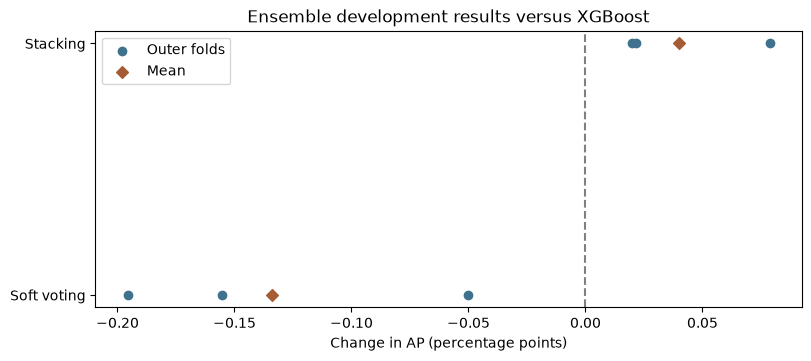

In [3]:
summary = scores.groupby('model', sort=False).agg(
    ap_mean=('ap', 'mean'), ap_sd=('ap', 'std'), roc_auc_mean=('roc_auc', 'mean'),
    brier_mean=('brier', 'mean'), top10_precision_mean=('top10_precision', 'mean'),
    top10_recall_mean=('top10_recall', 'mean'), defaults_caught=('defaults_caught', 'sum'),
    reviewed=('reviewed', 'sum'),
).sort_values('ap_mean', ascending=False)
best_single = summary.loc[list(MEMBERS.values()) + ['Logistic Regression'], 'ap_mean'].idxmax()
summary['ap_change_vs_best_single_pp'] = 100 * (summary['ap_mean'] - summary.loc[best_single, 'ap_mean'])
summary.to_csv(tables / 'ensemble_comparison.csv')
display(summary.round(4))

fold_ap = scores.pivot(index='fold', columns='model', values='ap')
deltas = 100 * fold_ap[list(METHODS)].sub(fold_ap[best_single], axis=0)
display(deltas.round(3).rename_axis(f'Fold | AP change vs {best_single} (percentage points)'))

fig, ax = plt.subplots(figsize=(8, 3.5), layout='constrained')
for i, name in enumerate(METHODS):
    ax.scatter(deltas[name], np.full(len(deltas), i), color='#40728E', label='Outer folds' if i == 0 else None)
    ax.scatter(deltas[name].mean(), i, marker='D', color='#A55C35', label='Mean' if i == 0 else None)
ax.axvline(0, linestyle='--', color='grey')
ax.set(yticks=np.arange(len(METHODS)), yticklabels=METHODS, xlabel='Change in AP (percentage points)',
       title=f'Ensemble development results versus {best_single}')
ax.legend()
fig.savefig(figures / 'ensemble_ap_comparison.png', dpi=160)
plt.show()

## 4. Check whether the two models complement each other

In [4]:
display(overlap.round(4))
best_ensemble = summary.loc[list(METHODS), 'ap_mean'].idxmax()
chosen = summary.loc[best_ensemble]
single = summary.loc[best_single]
print(f'Carry forward {best_ensemble}. Mean AP {chosen.ap_mean:.5f}; '
      f'{chosen.ap_change_vs_best_single_pp:+.3f} pp versus {best_single}.')
print(f'At the same review budget: {int(chosen.defaults_caught):,} defaults caught by {best_ensemble}; '
      f'{int(single.defaults_caught):,} by {best_single}.')
print(f'The two base rankings had mean Spearman correlation {overlap.spearman_rank_correlation.mean():.3f}.')

,fold,spearman_rank_correlation,queue_jaccard,defaults_caught_by_both,defaults_caught_only_by_xgb,defaults_caught_only_by_rf,defaults_caught_by_neither,stack_xgb_coefficient,stack_rf_coefficient
0,1,0.9491,0.7239,2481,330,273,6687,4.5412,1.3680
1,2,0.9476,0.7322,2507,337,272,6654,4.4470,1.4335
2,3,0.9468,0.7371,2518,337,247,6668,4.6144,1.1990


Carry forward Stacking. Mean AP 0.57979; +0.040 pp versus XGBoost.
At the same review budget: 8,509 defaults caught by Stacking; 8,510 by XGBoost.
The two base rankings had mean Spearman correlation 0.948.


## 5. Save the Part H handoff



In [5]:
final_settings = json.loads((part_f / 'selected_parameters.json').read_text(encoding='utf-8'))
handoff = {
    'method': best_ensemble,
    'members': list(MEMBERS.values()),
    'member_parameters': {name: final_settings[name] for name in MEMBERS.values()},
}
future_ensemble = make_ensemble(handoff['method'], handoff['member_parameters'])
assert [name for name, _ in future_ensemble.estimators] == list(MEMBERS)
(tables / 'selected_ensemble.json').write_text(json.dumps(handoff, indent=2), encoding='utf-8')
print(json.dumps(handoff, indent=2))

{
  "method": "Stacking",
  "members": [
    "XGBoost",
    "Random Forest"
  ],
  "member_parameters": {
    "XGBoost": {
      "model__learning_rate": 0.05,
      "model__max_depth": 6,
      "model__n_estimators": 220
    },
    "Random Forest": {
      "model__max_depth": 18,
      "model__min_samples_leaf": 5,
      "model__n_estimators": 100
    }
  }
}
